# Abandono escolar em Roraima: o Censo Escolar no pipeline

Este notebook mostra, para o professor, quatro coisas:

1. **o pipeline com o Censo de 2007 a 2025**: além da infraestrutura, a base ganhou 7 grupos de colunas do Censo
   (matrículas, docentes, turmas e salas, equipamentos, oferta e turno, escola indígena, prédio e serviços);
2. **um filtro de saúde automático**, que olha só os preditores e nunca o abandono;
3. **o resultado oficial do Estudo E**, lido das saídas da execução única, sem rodar nada;
4. **uma exploração com os anos escolhidos** na célula de configuração, marcada como exploratória.

Os números saem sempre do código. As contas ficam em `notebooks/apoio_apresentacao.py`, que tem testes.

In [1]:
# ===== CONFIGURAÇÃO: mude só esta célula =====
ANO_INICIO = 2007        # 2019 para a janela da Gabi
ANO_FIM = 2025
GRUPOS = ["infraestrutura", "censo_matriculas", "censo_docentes", "censo_turmas_salas",
          "censo_equipamentos", "censo_oferta_turno", "censo_escola_indigena", "censo_predio_servicos"]
REMOVER_REDUNDANTES = True   # regra |r| > 0,90 entre preditores, só no treino
SEMENTES_MLP = 5

# Trava fixa, fora da configuração (apoio_apresentacao.py): o desfecho de 2025 (t = 2024) nunca entra em treino
# nem em teste; a avaliação usa no máximo t = 2023 (desfecho 2024).

In [2]:
# Coleta: dataset v0.2.0 (desfechos por etapa) + colunas dos grupos, de saida/base_atual.parquet
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import apoio_apresentacao as A
pd.set_option("display.max_rows", 200); pd.set_option("display.width", 200)

d_todos, cols = A.coleta(GRUPOS, 2007, 2025)
d = d_todos[d_todos["ano"].between(ANO_INICIO, ANO_FIM)]
por_ano, por_grupo = A.resumo_coleta(d, cols)
print(f"Anos {ANO_INICIO}–{ANO_FIM}: {len(d)} escolas-ano × etapa.  t = 2024 e 2025 aparecem só aqui, na contagem.")
display(por_ano.T)
display(por_grupo.set_index("grupo").T)

Anos 2007–2025: 7550 escolas-ano × etapa.  t = 2024 e 2025 aparecem só aqui, na contagem.


ano,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
etapa,,,,,,,,,,,,,,,,,,,
AF,233,233,232,230,242,249,246,251,249,256,255,257,255,252,250,251,252,258,257
EM,109,108,112,114,124,127,135,142,151,159,161,169,169,168,170,177,180,184,183


grupo,infraestrutura,censo_matriculas,censo_docentes,censo_turmas_salas,censo_equipamentos,censo_oferta_turno,censo_escola_indigena,censo_predio_servicos
colunas,4,37,15,16,10,16,1,29


In [3]:
# Saúde: o filtro mecânico de 6 regras do Estudo E, só com preditores
# (preenchimento nos anos escolhidos até 2024; informação, > 99% num valor, nos anos de treino)
anos_tr = A.anos_treino(d_todos, ANO_INICIO)
tab_saude, resumo_saude = A.saude(cols, ANO_INICIO, anos_tr)
print(f"Preenchimento medido em {ANO_INICIO}–2024; informação em t = {anos_tr.start}–{anos_tr.stop - 1}.")
display(resumo_saude)

Preenchimento medido em 2007–2024; informação em t = 2008–2021.


motivo,PASSA,PASSA (dimensão do artigo),informacao,preenchimento
grupo,,,,
infraestrutura,0,4,0,0
censo_matriculas,35,0,2,0
censo_docentes,15,0,0,0
censo_turmas_salas,16,0,0,0
censo_equipamentos,4,0,0,6
censo_oferta_turno,16,0,0,0
censo_escola_indigena,1,0,0,0
censo_predio_servicos,21,0,0,8


## Resultado oficial do Estudo E

É o resultado **oficial**: protocolo escrito antes, execução única, janela t = 2013–2018, colunas do Censo
**brutas**. A pergunta E1 é se as colunas aumentam o quanto se explica do abandono (S2 − S1, Ridge); a E2 é se
melhoram a lista de risco do ano seguinte contra a régua (abandono do ano anterior) e contra a B2.

O resultado foi **sobreajuste**: com colunas redundantes e contagens brutas, o modelo decora o treino e piora fora
dele. Por isso o ranking de importância por permutação do Estudo E **não é importância** e não aparece aqui.

E1 — S2 − S1 no R² fora da amostra (Ridge, Holm sobre AF e EM)


,etapa,modelo,diferenca,ic_lo,ic_hi,p_holm,veredito
0,AF,ridge,-0.1012,-0.2339,-0.0164,0.0192,NÃO ACRESCENTA
1,EM,ridge,-0.1683,-0.2580,-0.0921,0.0008,NÃO ACRESCENTA


E2 — F9 (A+ − régua) e F10 (B+ − B2), Recall@20%, Holm sobre 4 testes


,familia,etapa,comparacao,diferenca,ic_lo,ic_hi,p_holm,veredito
0,F9,AF,ridge A+ − B1R_lag,-0.0165,-0.1299,0.0638,1.0000,SEM GANHO PRÁTICO
1,F9,AF,mlp A+ − B1R_lag,-0.0594,-0.1479,0.0118,0.3823,SEM GANHO PRÁTICO
2,F9,EM,ridge A+ − B1R_lag,0.0345,-0.1146,0.1545,1.0000,INCONCLUSIVO
3,F9,EM,mlp A+ − B1R_lag,0.0767,-0.0564,0.1685,1.0000,INCONCLUSIVO
4,F10,AF,ridge B+ − B2,0.0905,-0.0067,0.1829,0.2671,INCONCLUSIVO
5,F10,AF,mlp B+ − B2,0.0397,-0.0207,0.0964,0.5855,SEM GANHO PRÁTICO
6,F10,EM,ridge B+ − B2,0.0191,-0.1042,0.1366,1.0000,INCONCLUSIVO
7,F10,EM,mlp B+ − B2,0.0266,-0.0622,0.1175,1.0000,INCONCLUSIVO


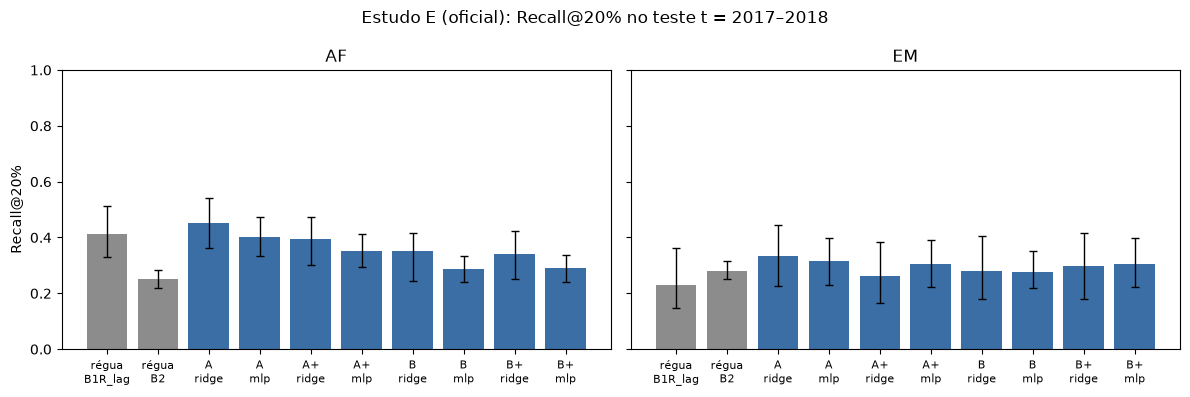

In [4]:
e1, e2, rec_e = A.resultado_e()
print("E1 — S2 − S1 no R² fora da amostra (Ridge, Holm sobre AF e EM)"); display(e1.round(4))
print("E2 — F9 (A+ − régua) e F10 (B+ − B2), Recall@20%, Holm sobre 4 testes"); display(e2.round(4))
A.barras_recall(rec_e, "Estudo E (oficial): Recall@20% no teste t = 2017–2018");

## ⚠️ EXPLORATÓRIA: a lista de risco com os anos escolhidos

**Nada desta parte decide nada.** Os anos de teste já foram vistos, e não há protocolo de execução única.

- **Teste fixo:** t = 2022 e 2023 (desfechos 2023 e 2024). **Treino:** de `ANO_INICIO` (ou do primeiro ano com o
  abandono do ano anterior) até t = 2021.
- **Universo:** o da Parte 2 do Estudo E. **Réguas:** B1R_lag e B2. **Modelos:** Ridge e o MLP do professor, nos
  conjuntos A, A+, B e B+.
- **Redundância:** com `REMOVER_REDUNDANTES`, sai a coluna com |r| > 0,90 com outra que veio antes, calculado só no
  treino.
- **Pré-processamento:** ajustado só no treino. As métricas trazem IC pelo bootstrap de escolas.

AF: treino t = 2008–2021 (3065 linhas), teste 455 linhas, 72 colunas do Censo no A+ e B+, 36 retiradas por redundância
   retiradas: QT_MAT_BAS_11_14, QT_MAT_BAS_FEM, QT_MAT_BAS_MASC, QT_MAT_BAS_N, QT_MAT_EJA, QT_MAT_EJA_MED, QT_MAT_ESP_CC, QT_MAT_FUND, QT_MAT_FUND_AI, QT_MAT_INF, QT_MAT_INF_CRE, QT_MAT_INF_INT, QT_MAT_INF_PRE, QT_MAT_MED, QT_MAT_PROF_TEC, QT_DOC_BAS, QT_DOC_EJA_MED, QT_DOC_ESP_CC, QT_DOC_FUND_AF, QT_DOC_FUND_AI, QT_DOC_INF_PRE, QT_DOC_PROF_TEC, QT_TUR_BAS, QT_TUR_EJA, QT_TUR_ESP, QT_TUR_ESP_CC, QT_TUR_FUND, QT_TUR_FUND_AF, QT_TUR_FUND_AI, QT_TUR_INF, QT_TUR_INF_CRE, QT_TUR_INF_PRE, QT_TUR_MED, QT_TUR_PROF, IN_ESP_CC, IN_INF_PRE
EM: treino t = 2008–2021 (1741 linhas), teste 320 linhas, 73 colunas do Censo no A+ e B+, 35 retiradas por redundância
   retiradas: QT_MAT_BAS_FEM, QT_MAT_BAS_MASC, QT_MAT_EJA_MED, QT_MAT_ESP_CC, QT_MAT_FUND, QT_MAT_FUND_AF, QT_MAT_FUND_AI, QT_MAT_INF_PRE, QT_MAT_MED, QT_MAT_PROF_TEC, QT_DOC_EJA_MED, QT_DOC_ESP_CC, QT_DOC_FUND_AF, QT_DOC_FUND_

valor                 IC 95%                
metrica                Recall@20%    MAE      Recall@20%             MAE
etapa conjunto modelo                                                   
AF    régua    B1R_lag      0.374    NaN  [0.289; 0.462]             NaN
               B2           0.250  3.135  [0.219; 0.285]  [2.868; 3.434]
      A        ridge        0.400  2.942  [0.307; 0.489]  [2.694; 3.231]
               mlp          0.392  2.872  [0.311; 0.474]  [2.622; 3.160]
      A+       ridge        0.422  2.907  [0.328; 0.507]  [2.642; 3.185]
               mlp          0.401  3.021  [0.332; 0.479]  [2.751; 3.305]
      B        ridge        0.285  3.545  [0.194; 0.376]  [3.282; 3.826]
               mlp          0.263  3.547  [0.186; 0.346]  [3.282; 3.828]
      B+       ridge        0.379  3.215  [0.272; 0.449]  [2.929; 3.513]
               mlp          0.322  3.322  [0.252; 0.397]  [3.045; 3.619]
EM    régua    B1R_lag      0.319    NaN  [0.214; 0.447]             NaN
               B2           0.266  5.508  [0.232; 0.300]  [4.965; 6.056]
      A        ridge        0.366  5.334  [0.248; 0.472]  [4.786; 5.884]
               mlp          0.357  5.305  [0.260; 0.457]  [4.752; 5.857]
      A+       ridge        0.335  5.163  [0.226; 0.439]  [4.594; 5.720]
               mlp          0.337  5.220  [0.238; 0.424]  [4.649; 5.759]
      B        ridge        0.281  5.823  [0.188; 0.407]  [5.300; 6.357]
               mlp          0.254  5.758  [0.159; 0.360]  [5.233; 6.287]
      B+       ridge        0.334  5.466  [0.229; 0.443]  [4.923; 5.978]
               mlp          0.336  5.423  [0.245; 0.425]  [4.889; 5.941]

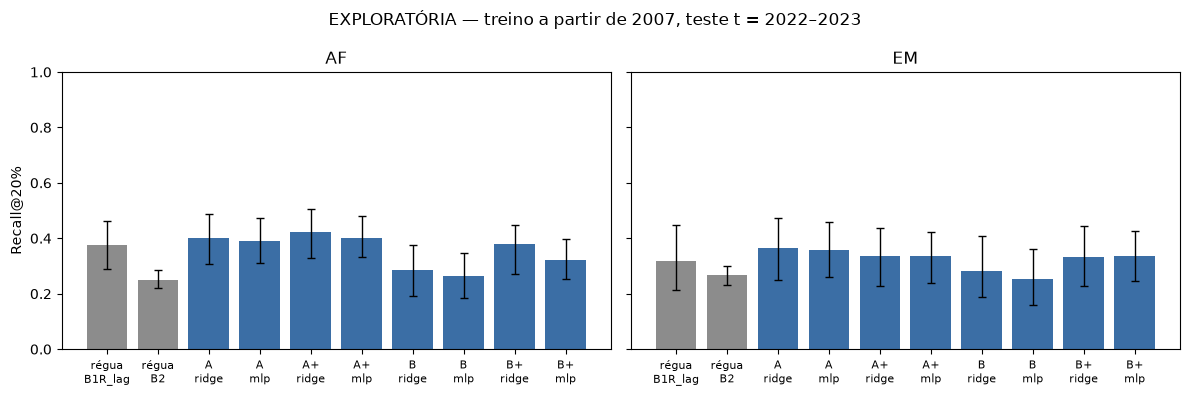

In [5]:
res = A.janela(d_todos, cols, ANO_INICIO, REMOVER_REDUNDANTES, SEMENTES_MLP)
for etapa, r in res.items():
    print(f"{etapa}: treino t = {r['anos_treino'][0]}–{r['anos_treino'][1]} ({r['n_treino']} linhas), "
          f"teste {r['n_teste']} linhas, {r['n_novas']} colunas do Censo no A+ e B+, "
          f"{len(r['retiradas'])} retiradas por redundância")
    if len(r["retiradas"]):
        print("   retiradas:", ", ".join(r["retiradas"]["coluna"]))
display(A.tabela(res).round(3))
A.barras_recall(A.recall_de(res), f"EXPLORATÓRIA — treino a partir de {ANO_INICIO}, teste t = 2022–2023");

## ⚠️ EXPLORATÓRIA: janela de treino 2007+ × 2019+

A célula anterior roda duas vezes, com `ANO_INICIO` = 2007 e 2019. O **teste é o mesmo** (t = 2022–2023) e tudo o
mais é igual; só a janela de treino muda, e com ela os anos do filtro de saúde e da redundância. A diferença
2019+ − 2007+ tem IC **pareado**: as mesmas reamostragens de escolas nas duas janelas.

- É **descritivo**. Escolher a janela pelo resultado num teste já visto não vale como prova.
- O treino de 2019+ cai nos anos de **pandemia** (desfechos 2020–2022).

A segunda tabela mostra, em cada janela, o Recall@20% de cada modelo menos o da régua B1R_lag, com IC pareado (as mesmas reamostragens). É descritiva, sem veredito: **IC passando por zero significa que não dá para afirmar que o modelo supera a régua.**

In [6]:
janelas = {ANO_INICIO: res}
for a in (2007, 2019):
    if a not in janelas:
        janelas[a] = A.janela(d_todos, cols, a, REMOVER_REDUNDANTES, SEMENTES_MLP)
comp = A.comparar(janelas[2007], janelas[2019], "2007+", "2019+")
display(comp.round(3))
print("Recall@20% de cada modelo − régua B1R_lag (descritivo; IC passando por zero: não dá para afirmar que supera a régua)")
display(A.contra_regua({f"{a}+": janelas[a] for a in (2007, 2019)}).round(3))

,etapa,conjunto,modelo,metrica,2007+,IC 2007+,2019+,IC 2019+,2019+ − 2007+,IC da diferença (pareado)
0,AF,régua,B1R_lag,Recall@20%,0.374,[0.289; 0.462],0.374,[0.289; 0.462],0.000,[0.000; 0.000]
1,AF,régua,B2,Recall@20%,0.250,[0.219; 0.285],0.250,[0.219; 0.285],0.000,[0.000; 0.000]
2,AF,régua,B2,MAE,3.135,[2.868; 3.434],2.547,[2.186; 2.964],-0.588,[-0.856; -0.293]
3,AF,A,ridge,Recall@20%,0.400,[0.307; 0.489],0.380,[0.287; 0.465],-0.021,[-0.135; 0.085]
4,AF,A,ridge,MAE,2.942,[2.694; 3.231],2.666,[2.370; 2.995],-0.276,[-0.429; -0.114]
5,AF,A,mlp,Recall@20%,0.392,[0.311; 0.474],0.320,[0.264; 0.390],-0.072,[-0.156; 0.020]
6,AF,A,mlp,MAE,2.872,[2.622; 3.160],2.826,[2.512; 3.170],-0.047,[-0.212; 0.130]
7,AF,A+,ridge,Recall@20%,0.422,[0.328; 0.507],0.379,[0.278; 0.469],-0.043,[-0.155; 0.072]
8,AF,A+,ridge,MAE,2.907,[2.642; 3.185],2.822,[2.539; 3.136],-0.085,[-0.272; 0.109]
9,AF,A+,mlp,Recall@20%,0.401,[0.332; 0.479],0.316,[0.253; 0.383],-0.085,[-0.166; -0.004]


Recall@20% de cada modelo − régua B1R_lag (descritivo; IC passando por zero: não dá para afirmar que supera a régua)


,janela,etapa,conjunto,modelo,modelo − B1R_lag,IC pareado
0,2007+,AF,A,ridge,0.026,[-0.069; 0.126]
1,2007+,AF,A,mlp,0.018,[-0.064; 0.109]
2,2007+,AF,A+,ridge,0.047,[-0.058; 0.146]
3,2007+,AF,A+,mlp,0.026,[-0.053; 0.120]
4,2007+,AF,B,ridge,-0.090,[-0.213; 0.035]
5,2007+,AF,B,mlp,-0.111,[-0.220; 0.006]
6,2007+,AF,B+,ridge,0.005,[-0.132; 0.104]
7,2007+,AF,B+,mlp,-0.052,[-0.160; 0.059]
8,2007+,EM,A,ridge,0.047,[-0.106; 0.167]
9,2007+,EM,A,mlp,0.038,[-0.101; 0.155]


## Ressalvas

- **Exploratório.** A parte com os anos escolhidos não tem protocolo de execução única e não decide nada.
- **Anos de teste já vistos.** Os desfechos de 2023 e 2024 já foram olhados.
- **Colunas brutas.** As colunas do Censo passaram só pelo filtro de saúde, sem a revisão coluna a coluna.
- **Pandemia.** Os desfechos de 2020 a 2022 caem no treino.
- **O teste limpo de 2025 fica fechado.** Nenhuma célula o usa, e nenhuma configuração o abre.
- **Próximo passo.** A limpeza coluna a coluna, guiada pela qualidade do dado e nunca pela métrica.